# Workflow: External Tools (Julia)

One of the main goals of VeriGym is to allow integration between a variety of existing tools and frameworks.
In this workflow, we show off the intergration with one such external framework: the `POMDPs.jl` format used to define and solve (PO)MDPs in the `Julia` programming language.

**What do we show here?**
In this workflow, we benchmark a standard RL algorithm against model checked ground-truth results with the following steps:
1. We construct an abstraction for the Gymnasium environment `X` and export it to UMB format.
2. In `Julia`, we import the model, solve it via an existing solver, and export a policy using `PRISM`s action list format.
3. We import the policy into VeriGym, and evaluate the policy on both the abstracted and original model.


## Imports and helpers

In [1]:
# set to False for a more elaborate run
QUICK = True

In [ ]:
# Imports
import gymnasium as gym
import os
import subprocess
import stormpy

# VeriGym
import verigym
from verigym.policy.randomized import RandomizedPolicy
from verigym.policy.qvalue import EntropyLearningPolicy
from verigym.io.exporter import export_to_umb, export_to_drn
from verigym.abstraction.abstractionmapper import AbstractionMapper, linspace_mapper
from verigym.frameworks.prism.prismpolicy import PrismPolicy
from verigym.frameworks.stormpy.stormpy_utils import build_stormpy_mdp

# Helpers
from workflow_utils import OUTPATH, run_eval_episodes, plot_compare_policy_eval
import plot_style

# Paths etc.
SUBPATH = "ext_tools_files/"
dir = f"{OUTPATH}/{SUBPATH}"
PLOT_PATH = f"{OUTPATH}/figures/{SUBPATH}"
os.makedirs(PLOT_PATH, exist_ok=True)
SEED = 1285821

## 1 - Construct and export abstraction
To start of, we pick an environment that we want to make an abstraction for. To keep things simple, we use the standard `gym` environment *CartPole*, and use a simple box discretization. For more details on how to construct and discretize models, see the other workflows.

In [3]:
gamma = 0.95  # discount factor

original_model = verigym.GenerativeEnv.from_gymnasium(gym.make("CartPole-v1"))

abstraction_mapper = linspace_mapper(
        env=original_model, 
        n_bins_states=11, 
        n_bins_actions=1
    )

abstracted_model = verigym.create_abstraction(
    original_model, 
    abstraction_mapper,
    exploration_policy=EntropyLearningPolicy(original_model, abstraction_mapper, seed=SEED),
    num_steps=(10 if QUICK else int(1e4)),
    n_iterations = 50,
    seed=SEED,
    multithreading=False
)

/home/merlijn/GitRepos/VeriGym/.venv/lib/python3.13/site-packages/numpy/_core/function_base.py:163: RuntimeWarning: invalid value encountered in multiply
  y *= step
/home/merlijn/GitRepos/VeriGym/.venv/lib/python3.13/site-packages/numpy/_core/function_base.py:173: RuntimeWarning: invalid value encountered in add
  y += start


Next, to use any external tool, we need to be able to *write* our constructed model to a file. VeriGym makes use of existing `stormpy` functionality to supports writing to the following formats:
* [Unified Markov Binary (UMB)](https://arxiv.org/abs/2606.17811);
* [Direct Encoding (DRN)](https://www.stormchecker.org/documentation/background/drn.html).

We chose DRN format, in which case exporting looks as follows:

In [4]:
export_to_umb(abstracted_model, dir + "model.umb")
export_to_drn(abstracted_model, dir + "model.drn")

WARN  (ArchiveWriter.cpp:102): Unexpected result from archive: Failed to open '/home/merlijn/GitRepos/VeriGym/docs/workflows/output/workflows/workflows/ext_tools_files/model.umb'.
ERROR (ArchiveWriter.cpp:107): Unexpected result from archive: Failed to open '/home/merlijn/GitRepos/VeriGym/docs/workflows/output/workflows/workflows/ext_tools_files/model.umb'.


/tmp/ipykernel_351870/1548479165.py:1: UserWarning: The initial state distribution is not uniform over the initial states, but UMB files only store the set of initial states: loading the file assumes a uniform distribution over them.
  export_to_umb(abstracted_model, dir + "model.umb")


RuntimeError: FileIoException: Unexpected result from archive: Failed to open '/home/merlijn/GitRepos/VeriGym/docs/workflows/output/workflows/workflows/ext_tools_files/model.umb'.

## 2 - External Policy Computation

Since our model is now exported into a standard format, we can use external solvers to compute a policy. For this example, we use `MCTS.jl`, which is a `Julia` program that requires the model in `POMDPs.jl` format. VeriGym includes a number of `Julia` scripts that simplify this process. More precisely, this includes code to import and export MDPs in UMB format, and export policies in [Prisms explicit action list format](https://prismmodelchecker.org/manual/RunningPRISM/Strategies). Using this functionality, we can run a simple `Julia` script to compute and export a policy as follows:


```julia
using POMDPs
using MCTS

# Import our code
include("../src/verigym/external/julia/POMDPs_UMB.jl")
import .POMDPs_UMB

# Read the model
dir = "./working_directory/"
input, output = dir * "model.umb", dir * "policy.txt"
model = POMDPs_UMB.read_umb(input; discount=0.95)

# Solve using POMDPs.jl solver
solver = MCTSSolver()
planner = solve(solver, model)

# Export policy
policy = POMDPs_UMB.Explicit_policy(planner, model)
POMDPs_UMB.write_policy(output, policy)
println("Policy computation complete!")
```

The resulting policy file is already available, but can be re-computed by running the code below. Note that this requires you to have installed `Julia`, as well as the `POMDPs` and `MCTS` modules.

In [ ]:
if True: # set to false to skip (e.g., if julia is not installed):
    n_iterations = (10 if QUICK else 5000)
    subprocess.call(["julia", "./workflow_external_tools_script.jl", "--seed", str(SEED), "--n_iterations", str(n_iterations)])

Policy computation complete! (In 7.726016998291016s, achieving value 9.494507785453125


To use the computed policy, we use `VeriGym`'s functionality for importing policies in Prism format:

In [ ]:
policy_path = "./workflows/ext_tools_files/policy.txt"

julia_policy = PrismPolicy(policy_path=policy_path, abstraction_mapper=abstraction_mapper)

# 3 - Policy Evaluation

We can now use the imported policy the way we would any other policy. As an example, we here compare it's performance agains that of a Stormpy policy:

In [ ]:
stormpy_mdp = build_stormpy_mdp(abstracted_model)

prop = stormpy.parse_properties(f"Rmax=?[Cdiscount={gamma}]")[
    0
]  # checking for cumulative discounted reward

# Run the model checking:
result = stormpy.check_model_sparse(stormpy_mdp, prop, extract_scheduler=True)
stormpy_policy = verigym.StormpyPolicy(result.scheduler, abstracted_model.abstraction_map, stormpy_mdp)

/home/merlijn/GitRepos/VeriGym/docs/workflows/workflow_utils.py:373: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


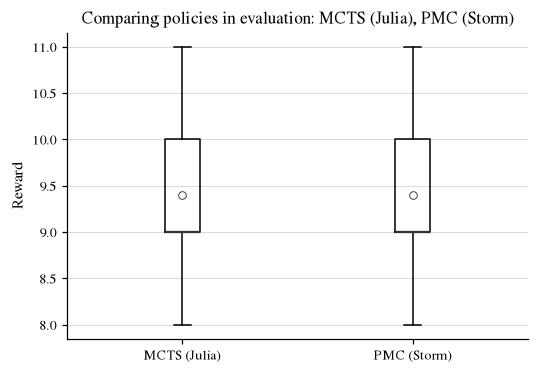

In [ ]:
jl_eval = run_eval_episodes(original_model, julia_policy)
sp_eval = run_eval_episodes(original_model, stormpy_policy)

plot_compare_policy_eval([jl_eval, sp_eval], ["MCTS (Julia)", "PMC (Storm)"],
                         path_output=f"{PLOT_PATH}/mcts_vs_model_checking.pdf")